In [1]:
%load_ext autoreload
%autoreload 2
import os
import shutil

In [2]:
from CrocoDash.grid import Grid

grid = Grid.from_supergrid("replica_grid.nc")

In [3]:
from CrocoDash.topo import Topo

topo = Topo(
    grid = grid,
    min_depth = 9.5,
)

In [4]:
import xarray as xr
import regional_mom6 as rmom6
from pathlib import Path
expt = rmom6.experiment.create_empty()

# Note: What regional_mom6 calls the hgrid is actually the supergrid
class HGrid:
    pass

expt.hgrid = HGrid()
expt.hgrid.x = xr.DataArray(topo._grid._supergrid.x, dims=("nyp", "nxp"))
expt.hgrid.y = xr.DataArray(topo._grid._supergrid.y, dims=("nyp", "nxp"))
expt.latitude_extent = [
    topo._grid._supergrid.y.min(),
    topo._grid._supergrid.y.max(),
]
expt.longitude_extent = [
    topo._grid._supergrid.x.min(),
    topo._grid._supergrid.x.max(),
]
expt.mom_input_dir = Path("/glade/u/home/manishrv/documents/croc/dev/regional_cice_mom6/subset_pan_artic")

In [16]:
bathy = xr.open_dataset("regridding_gebco_bathy.nc")
bathy["depth"] = bathy["elevation"]

In [17]:
bathy = expt.tidy_bathymetry(bathymetry = bathy,positive_down = False)
topo._depth = bathy.depth

Tidy bathymetry: Reading in regridded bathymetry to fix up metadata...done. Filling in inland lakes and channels... 

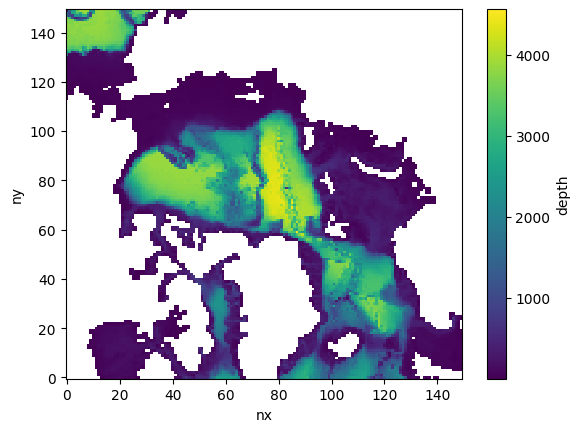

In [18]:
bathy.depth.plot()

In [19]:
from CrocoDash.vgrid import VGrid

vgrid  = VGrid.hyperbolic(
    nk = 75,
    depth = topo.max_depth,
    ratio=20.0
)

In [20]:
topo.write_topo("corrected_topo_regrid.nc")

In [21]:
vgrid.write("corrected_vgrid.nc")

In [22]:
from pathlib import Path

In [23]:
# CESM case (experiment) name
casename = "cice.cd.3"

# CESM source root (Update this path accordingly!!!)
cesmroot = Path("/glade/u/home/manishrv/work/installs/CROCESM_beta04_clean")

# Place where all your input files go 
inputdir = Path.home() / "scratch" / "croc_input" / casename
    
# CESM case directory
caseroot = Path.home() / "croc_cases" / casename

In [24]:
# Compset - 1850_DATM%JRA_SLND_CICE_MOM6_SROF_SGLC_SWAV
from CrocoDash.case import Case
grid.name = "cice_test_cd"
case = Case(
    cesmroot = cesmroot,
    caseroot = caseroot,
    inputdir = inputdir,
    ocn_grid = grid,
    ocn_vgrid = vgrid,
    ocn_topo = topo,
    project = 'NCGD0011',
    override = True,
    machine="derecho")

INFO:  csp_solver:CspSolver initialized.


Creating case...

• Updating ccs_config/modelgrid_aliases_nuopc.xml file to include the new resolution "cice.cd.3" consisting of the following component grids.
 atm grid: "TL319", lnd grid: "TL319", ocn grid: "cice_test_cd".

• Updating ccs_config/component_grids_nuopc.xml file to include newly generated ocean grid "cice_test_cd" with the following properties:
 nx: 150, ny: 150. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/cice.cd.3/ocnice/ESMF_mesh_cice_test_cd_bb5f88.nc.

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/CROCESM_beta04_clean/cime/scripts/create_newcase --compset 1850_DATM%JRA_SLND_CICE_MOM6_SROF_SGLC_SWAV --res cice.cd.3 --case /glade/u/home/manishrv/croc_cases/cice.cd.3 --machine derecho --run-unsupported --project NCGD0011 --non-local 

The create_newcase command was successful.

Navigating to the case directory:

cd /glade/u/home/manishrv/croc_cases/cice.cd.3

Apply NTASK grid xml changes:

./xmlchange NTASK

INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/manishrv/croc_cases/cice.cd.3.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.



In [25]:
case.configure_forcings(
    date_range = ["1993-01-01 00:00:00", "1993-01-06 00:00:00"]
)

INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/derecho/scratch/manishrv/tmp/tmpmaldbdc0/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/manishrv/scratch/croc_input/cice.cd.3/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/manishrv/scratch/croc_input/cice.cd.3/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/manishrv/scratch/croc_input/cice.cd.3/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoDash.raw_data_access.datasets.glorys:This data access method retuns a script at path /glade/u/home/manishrv/scratch/croc_input/cice.cd.3/glorys/get_glorys_data.sh to run to get access data 
INFO:CrocoD

This means that some areas may only have one or two layers between the surface and sea floor. 
For increased stability, consider increasing the minimum depth, or adjusting the vertical coordinate to add more layers near the surface.


In [26]:
case.process_forcings(process_initial_condition=False, process_velocity_tracers=False)

Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  SURFACE_HEIGHT_IC_VAR = eta_t
  VELOCITY_CONFIG = file
  VELOCITY_FILE = init_vel.nc

  ! Open boundary conditions
  OBC_NUMBER_OF_SEGMENTS = 4
  OBC_FREESLIP_VORTICITY = False
  OBC_FREESLIP_STRAIN = False
  OBC_COMPUTED_VORTICITY = True
  OBC_COMPUTED_STRAIN = True
  OBC_ZERO_BIHARMONIC = True
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_OUT = 3.0E+04
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_IN = 3000.0
  BRUSHCUTTER_MODE = True
  OBC_SEGMENT_001 = "J=0,I=0:N,FLATHER,ORLANSKI,NUDGED,ORLANSKI_TAN,NUDGED_TAN"
  OBC_SEGMENT_001_VELOCITY_NUDGING_TIMESCALES = 0.3, 360.0
  OBC_SEGMENT_001_DATA = "U=file:forcing_obc_segment_001.nc(u),V=file:forcing_obc_segment_001.nc(v),SSH=file:forcing_obc_

In [27]:
topo.write_cice_grid("/glade/u/home/manishrv/scratch/croc_input/cice.cd.3/ocnice/cice_grid.nc")

# Post Setup
1. Copy the MOM_input Kate has
1. Copy the datm_streams.xml

In [28]:
source_file = "/glade/derecho/scratch/manishrv/pan_artic_files_kate/MOM_input"
destination_file = caseroot/"SourceMods/src.mom/MOM_input"
shutil.copy(source_file, destination_file)

PosixPath('/glade/u/home/manishrv/croc_cases/cice.cd.3/SourceMods/src.mom/MOM_input')

In [17]:
source_file = "/glade/derecho/scratch/manishrv/pan_artic_files_kate/seawifs-clim-1997-2010.smoothed.nc"
destination_file = inputdir/"ocnice/seawifs-clim-1997-2010.smoothed.nc"
shutil.copy(source_file, destination_file)

source_file = "/glade/derecho/scratch/manishrv/pan_artic_files_kate/tidal_amplitude_Artic_12k.nc"
destination_file = inputdir/"ocnice/tidal_amplitude_Arctic_12k.nc"
shutil.copy(source_file, destination_file)

PosixPath('/glade/u/home/manishrv/scratch/croc_input/cice.kate.1/ocnice/tidal_amplitude_Arctic_12k.nc')

In [18]:
topo.write_cice_grid(inputdir/ "cice_grid.nc")


In [ ]:
# Add USE_CFC_CAP=False to user_nl_mom
# Generate the CICE grids using the tool in my dev director, pass in the correct grid and such: /glade/u/home/manishrv/documents/croc/dev/regional_cice_mom6/output_hgrid_with_pop_info.py
# Add lines to user_nl_cice and READ_TIDEAMP = False in MOM6 for now. H2_FILE = ocean_topog_cice_test_1_eaf771.nc
# Add H2 field to topog file or copy from my existing topog file, it's from Kate's files: /glade/derecho/scratch/manishrv/croc_input/cice.test.1/ocnice/ocean_topog_cice_test_1_eaf771.nc
# Add Masking Depth Change to -9999 (the default) in user_nl_mom
# Remove CrocoDash DT changes
# NCPL changes!                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    
